In [ ]:
#TRAIN RMS autoencoder

In [2]:
import torch                     # Core PyTorch library
import torch.nn as nn            # Neural network building blocks
import torch.nn.functional as F  # Common activation functions and utilities

In [3]:
import numpy as np

data = np.load("RMS-features.npy")

np.random.seed(42)
np.random.shuffle(data)

split_idx = int(len(data) * 0.9)
train_data = data[:split_idx]
val_data = data[split_idx:]

print(train_data.shape, val_data.shape)

(50352, 20) (5595, 20)


In [5]:
from torch.utils.data import TensorDataset, DataLoader

train_tensor = torch.tensor(train_data, dtype=torch.float32)
dataset = TensorDataset(train_tensor)
dataloader = DataLoader(dataset, batch_size=64, shuffle=True)

In [6]:
class RMSAutoencoder(nn.Module):
    def __init__(self, input_dim=20, latent_dim=2, hidden_dim=16):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim)
        )

    def forward(self, x):
        z = self.encoder(x)
        recon_x = self.decoder(z)
        return recon_x, z

In [7]:
model_rms = RMSAutoencoder(input_dim=20, latent_dim=2)
optimizer = torch.optim.Adam(model_rms.parameters(), lr=1e-4)
num_epochs = 100

for epoch in range(num_epochs):
    for batch in dataloader:
        x = batch[0]
        recon_x, z = model_rms(x)
        loss = F.mse_loss(recon_x, x, reduction='mean')
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    if (epoch+1) % 10 == 0:
        print(f"Epoch {epoch+1}, Loss: {loss.item():.4f}")

/Users/daria/opt/anaconda3/envs/c4dm/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Epoch 10, Loss: 0.0004
Epoch 20, Loss: 0.0004
Epoch 30, Loss: 0.0005
Epoch 40, Loss: 0.0005
Epoch 50, Loss: 0.0015
Epoch 60, Loss: 0.0004
Epoch 70, Loss: 0.0005
Epoch 80, Loss: 0.0008
Epoch 90, Loss: 0.0013
Epoch 100, Loss: 0.0002


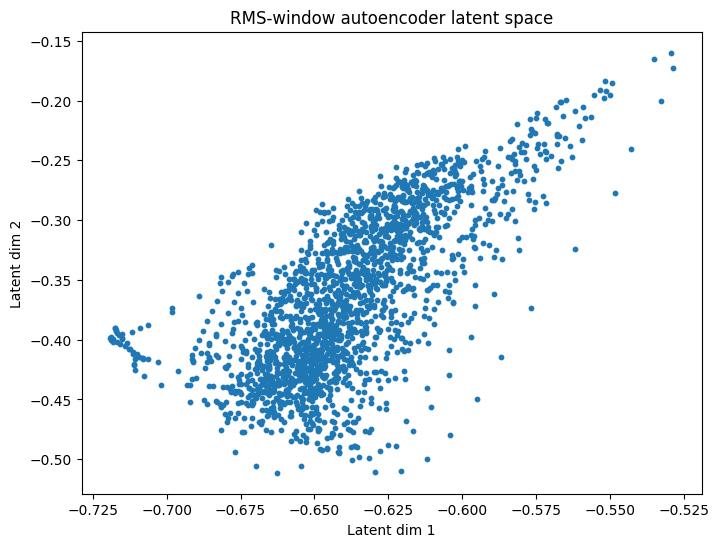

In [9]:
import librosa
import numpy as np
import matplotlib.pyplot as plt

def extract_rms_windows(filepath, window_size=20, step=1):
    y, sr = librosa.load(str(filepath), sr=44100, mono=True)
    rms = librosa.feature.rms(y=y)[0]

    windows = []
    for i in range(0, len(rms) - window_size, step):
        window = rms[i:i + window_size]
        windows.append(window)

    return np.array(windows)


model_rms.eval()

test_clip_windows = extract_rms_windows("../daria-recordings/chitara-pt-cod.wav")  # same clip as your other tests
test_tensor = torch.tensor(test_clip_windows, dtype=torch.float32)

with torch.no_grad():
    z = model_rms.encoder(test_tensor)

z_np = z.numpy()

plt.figure(figsize=(8,6))
plt.scatter(z_np[:,0], z_np[:,1], s=10)
plt.xlabel("Latent dim 1")
plt.ylabel("Latent dim 2")
plt.title("RMS-window autoencoder latent space")
plt.show()

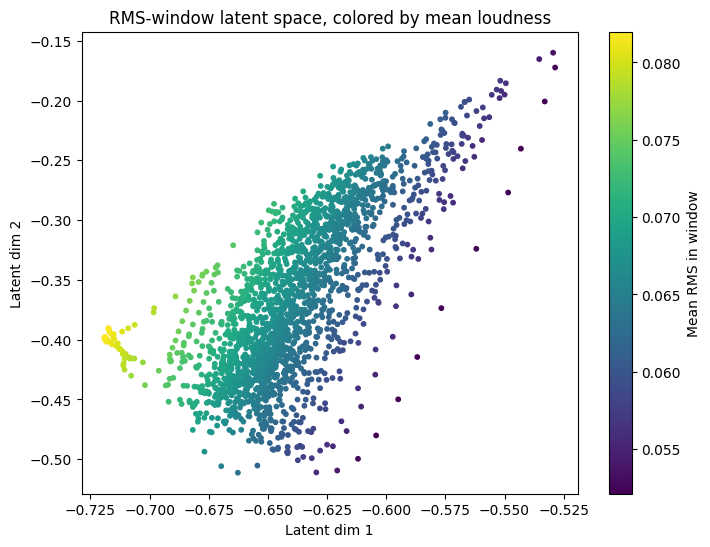

In [10]:
avg_rms_per_window = test_clip_windows.mean(axis=1)

plt.figure(figsize=(8,6))
scatter = plt.scatter(z_np[:,0], z_np[:,1], c=avg_rms_per_window, cmap='viridis', s=10)
plt.colorbar(scatter, label="Mean RMS in window")
plt.xlabel("Latent dim 1")
plt.ylabel("Latent dim 2")
plt.title("RMS-window latent space, colored by mean loudness")
plt.show()



In [11]:
torch.save(model_rms.state_dict(), "rms_autoencoder.pt")